Step 1: Load the data. Loaded the Students Performance dataset (1,000 records, 8 columns) using Pandas.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance.csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("StudentsPerformance.csv")

print(df.shape)
df.head()

(1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


Step 2: Data cleaning. Standardized column names, checked for missing values and duplicates (none found), converted categorical columns to the category type, and added an average score column.

In [5]:
df.columns = (df.columns.str.strip()
                         .str.lower()
                         .str.replace("/", "_")
                         .str.replace(" ", "_"))
print(df.columns.tolist())

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


In [6]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64
Duplicates: 0


In [7]:
df = df.drop_duplicates()
print(df.shape)

(1000, 8)


In [8]:
cat_cols = ["gender", "race_ethnicity", "parental_level_of_education",
            "lunch", "test_preparation_course"]

for col in cat_cols:
    df[col] = df[col].astype("category")

df.dtypes

,0
gender,category
race_ethnicity,category
parental_level_of_education,category
lunch,category
test_preparation_course,category
math_score,int64
reading_score,int64
writing_score,int64


In [9]:
df["average_score"] = df[["math_score", "reading_score", "writing_score"]].mean(axis=1).round(2)
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67
1,female,group C,some college,standard,completed,69,90,88,82.33
2,female,group B,master's degree,standard,none,90,95,93,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33
4,male,group C,some college,standard,none,76,78,75,76.33


In [11]:
score_cols = ["math_score", "reading_score", "writing_score"]

In [12]:
df.groupby("test_preparation_course", observed=True)[score_cols].mean().round(2)

,math_score,reading_score,writing_score
test_preparation_course,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


Students who completed the test preparation course scored higher than those who didn’t in all three subjects. The gap is smallest in math (about 5.6 points) and largest in writing (about 9.9 points).

In [13]:
df.groupby("lunch", observed=True)[score_cols].mean().round(2)

,math_score,reading_score,writing_score
lunch,,,
free/reduced,58.92,64.65,63.02
standard,70.03,71.65,70.82


Students with a standard lunch scored higher than those with a free/reduced lunch in every subject. The gap is largest in math (about 11 points) and about 7 to 8 points in reading and writing.

In [14]:
order = ["some high school", "high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]

parent = (df.groupby("parental_level_of_education", observed=True)[score_cols]
            .mean().round(2).reindex(order))
parent

,math_score,reading_score,writing_score
parental_level_of_education,,,
some high school,63.50,66.94,64.89
high school,62.14,64.70,62.45
some college,67.13,69.46,68.84
associate's degree,67.88,70.93,69.90
bachelor's degree,69.39,73.00,73.38
master's degree,69.75,75.37,75.68


Scores generally rise with the parent’s education level. Students whose parents hold a master’s degree have the highest reading and writing averages, while those whose parents finished only high school have the lowest scores in all three subjects. The trend isn’t perfectly smooth, since “some high school” is slightly higher than “high school”. The gap between the lowest and highest groups is about 7.6 points in math, 10.7 in reading, and 13.2 in writing.

In [15]:
df.groupby("gender", observed=True)[score_cols].mean().round(2)

,math_score,reading_score,writing_score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


Male students scored higher in math (about 5 points), while female students scored higher in reading (about 7 points) and writing (about 9 points).

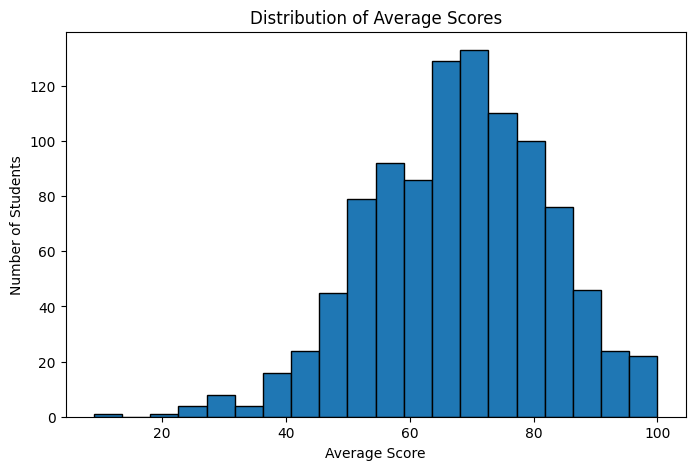

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df["average_score"], bins=20, edgecolor="black")
plt.title("Distribution of Average Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")
plt.savefig("chart1_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Most students’ average scores fall between about 60 and 80, with few students at the extremes.

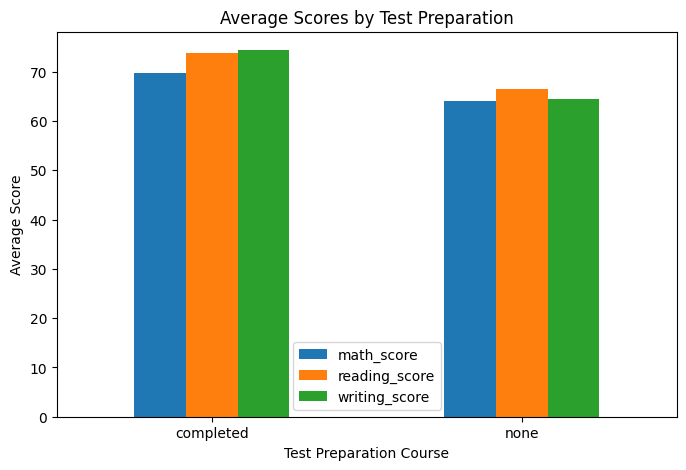

In [17]:
prep = df.groupby("test_preparation_course", observed=True)[score_cols].mean()

prep.plot(kind="bar", figsize=(8, 5))
plt.title("Average Scores by Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.savefig("chart2_test_prep.png", dpi=150, bbox_inches="tight")
plt.show()

Students who completed test preparation have higher average scores in all three subjects.

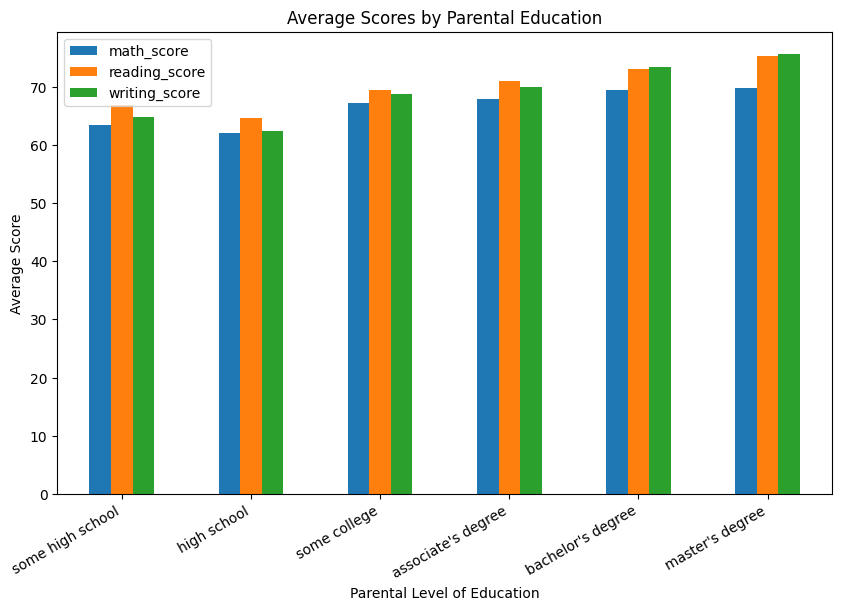

In [18]:
parent.plot(kind="bar", figsize=(10, 6))
plt.title("Average Scores by Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Score")
plt.xticks(rotation=30, ha="right")
plt.savefig("chart3_parental_education.png", dpi=150, bbox_inches="tight")
plt.show()

Average scores tend to rise with parental education level, with the lowest scores in the high school group.

## Key Findings
- Students who completed test preparation scored higher in all three subjects, with the largest gap in writing (about 9.9 points).
- Students with a standard lunch scored about 7 to 11 points higher than those with free/reduced lunch, with the largest gap in math.
- Average scores generally rise with parental education level, with the lowest scores in the high school group and the highest reading and writing scores in the master's degree group.
- Male students scored higher in math, while female students scored higher in reading and writing.

Note: These results show differences between groups in this dataset only and do not prove cause and effect.